# StatsForecast

`StatsForecastAdapter` is the most capable adapter in the package: it is the
only one whose support for every capability is unconditional, so all six
methods work behind it whatever model you wrap. `NeuralForecastAdapter`
declares the same set, but its quantile support depends on the model's loss.

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from statsforecast import StatsForecast
from statsforecast.models import AutoETS, SeasonalNaive

from conformalforecast import (
    ConformalizedQuantileRegression,
    SplitConformal,
    SupportsCrossValidationQuantiles,
    SupportsQuantiles,
    SupportsRefit,
)
from conformalforecast import (
    panel as P,
)
from conformalforecast.adapters import StatsForecastAdapter
from conformalforecast.diagnostics import coverage_by_series, evaluate

HORIZON, SEASON, ALPHA = 24, 24, 0.1
N_HOLDOUT = 4

df = pd.read_csv("nbs/data/m4_hourly_panel.csv", parse_dates=["ds"])
matrix, index = P.long_to_panel(df["y"].to_numpy(), df["unique_id"].to_numpy(), df["ds"].to_numpy())
print("panel", matrix.shape, "over", len(index.series_ids), "series")

# Hold the tail out before anything is fitted, so the coverage measured at the
# end of this page is measured on data no part of the pipeline has seen.
train_df = df[df["ds"] <= df["ds"].max() - pd.Timedelta(hours=N_HOLDOUT * HORIZON)].reset_index(
    drop=True
)
print("training through", train_df["ds"].max(), f"({N_HOLDOUT * HORIZON} hours held out)")

panel (8, 672) over 8 series
training through 2015-01-24 23:00:00 (96 hours held out)


## Fit first, wrap second

The adapter does not fit anything. Build and fit your `StatsForecast` object
exactly as you normally would, then hand it over along with the frame it was
trained on as the adapter needs that to reconstruct histories at the right
frequency.

In [ ]:
sf = StatsForecast(models=[AutoETS(season_length=SEASON)], freq="h", n_jobs=1)
sf.fit(train_df)

forecaster = StatsForecastAdapter(
    sf=sf,
    train_df=train_df,
    horizon=HORIZON,
    freq="h",
    model_name="AutoETS",  # which of the fitted models this adapter speaks for
)

for capability in (SupportsRefit, SupportsQuantiles, SupportsCrossValidationQuantiles):
    print(f"{capability.__name__:34s} {forecaster.supports(capability)}")

SupportsRefit                      True
SupportsQuantiles                  True
SupportsCrossValidationQuantiles   True


`model_name` picks one column out of the fitted output. One adapter speaks for
one model, so wrapping the same `sf` twice conformalizes two of its models
independently.

::: {.callout-warning}
## One caveat on sharing a multi-model `StatsForecast`

Cross-validation runs at the `StatsForecast` level, not per column. If the object
holds several models and *any* of them lacks a `forward` method, `refit=False`
fails for all of them — even for an adapter that only reads the `AutoETS` column.
That is why this page builds a second `StatsForecast` below rather than adding
`SeasonalNaive` to the one above.
:::

## Calibrating

In [ ]:
split = SplitConformal(alpha=ALPHA).calibrate_cv(forecaster, n_windows=30)
print("effective windows:", split.n_calibration_samples_)

prediction = split.predict(matrix)
print("point   ", prediction.point.shape)
print("interval", prediction.interval.shape)

effective windows: [30 30 30 30 30 30 30 30]


point    (8, 1, 24)
interval (8, 1, 24, 2)


::: {.callout-note}
## `refit` depends on the model, not on you

`calibrate_cv(refit=False)` — the default — asks statsforecast to reuse fitted
parameters across cutoffs via each model's `forward` method. `AutoETS` has one,
so the call above is fast. `SeasonalNaive` does not, and statsforecast raises
`ValueError: ... The following models do not implement the forward method` —
pass `refit=True` for those.
:::

In [ ]:
sf_naive = StatsForecast(models=[SeasonalNaive(season_length=SEASON)], freq="h", n_jobs=1)
sf_naive.fit(train_df)

naive_forecaster = StatsForecastAdapter(
    sf=sf_naive, train_df=train_df, horizon=HORIZON, freq="h", model_name="SeasonalNaive"
)
naive = SplitConformal(alpha=ALPHA).calibrate_cv(
    naive_forecaster, n_windows=30, refit=True
)  # refit=False would raise
print("SeasonalNaive calibrated with refit=True")

SeasonalNaive calibrated with refit=True


## Polars frames

The adapter takes a polars `train_df` just as well, and conformalforecast installs
neither library. Pass the same `freq` you gave StatsForecast; for polars that is a
polars interval, `"1h"`, rather than the pandas alias `"h"`. Every frame the adapter
hands StatsForecast stays polars, and the calibrated quantile matches the pandas run.

In [ ]:
import polars as pl

train_pl = pl.DataFrame({c: train_df[c].to_numpy() for c in train_df.columns})
sf_pl = StatsForecast(models=[SeasonalNaive(season_length=SEASON)], freq="1h", n_jobs=1)
sf_pl.fit(train_pl)

naive_forecaster_pl = StatsForecastAdapter(
    sf=sf_pl, train_df=train_pl, horizon=HORIZON, freq="1h", model_name="SeasonalNaive"
)
naive_pl = SplitConformal(alpha=ALPHA).calibrate_cv(naive_forecaster_pl, n_windows=30, refit=True)
print(type(naive_forecaster_pl.train_df).__module__)
print("same quantile as pandas:", np.allclose(naive_pl.score_quantile_, naive.score_quantile_))

polars.dataframe.frame
same quantile as pandas: True


## Per-series intervals

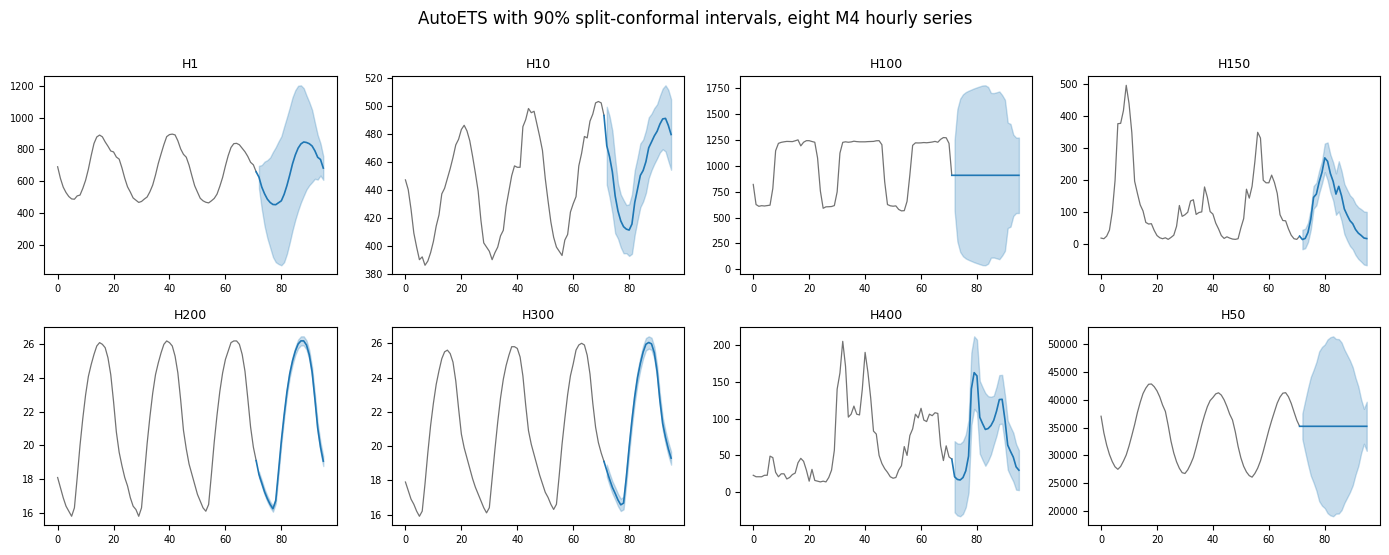

In [ ]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.5))
context = 72

for s, ax in enumerate(axes.ravel()):
    history = matrix[s]
    observed = history[~np.isnan(history)][-context:]
    past = np.arange(len(observed))
    future = np.arange(len(observed), len(observed) + HORIZON)
    join = np.r_[past[-1], future]

    ax.plot(past, observed, color="0.45", lw=0.9)
    ax.plot(join, np.r_[observed[-1], prediction.point[s, 0]], color="C0", lw=1.2)
    ax.fill_between(
        future,
        prediction.interval[s, 0, :, 0],
        prediction.interval[s, 0, :, 1],
        color="C0",
        alpha=0.25,
    )
    ax.set_title(index.series_ids[s], fontsize=9)
    ax.tick_params(labelsize=7)

fig.suptitle("AutoETS with 90% split-conformal intervals, eight M4 hourly series", y=1.0)
fig.tight_layout()

Eight series, eight scales — and each band is calibrated on that series' own
residuals. Nothing here is a global multiplier.

## Quantiles, and CQR

`StatsForecastAdapter` exposes statsforecast's analytical prediction intervals as
quantiles, which is what makes [CQR](../methods/cqr.html) available.

In [ ]:
cqr = ConformalizedQuantileRegression(alpha=ALPHA)
cqr_fitted = cqr.calibrate_cv(forecaster, n_windows=30)
print("quantile levels requested from statsforecast:", cqr.quantile_levels)

quantile levels requested from statsforecast: [0.05 0.95]


::: {.callout-warning}
## Two rules statsforecast imposes on quantiles

- **Symmetric pairs only.** Quantiles are requested through statsforecast's
  *level* API, so 0.05 must be accompanied by 0.95. Asking for an unpaired
  quantile raises `ValueError` in the adapter. This is shared with the
  mlforecast and neuralforecast adapters, so asymmetric CQR (`symmetric=False`)
  is out of reach for all three — see [CQR](../methods/cqr.html) for the detail.
- **No median.** `q == 0.5` is rejected; the level API has no column for it.

`alpha` is translated into a legal pair for you, so you only meet these rules if
you specify levels by hand.
:::

## Exogenous regressors

An `exog_features` argument tells the adapter which columns of `train_df` are
regressors rather than the target.

::: {.callout-important}
## Declaring `exog_features` removes the quantile capability

This is the package's canonical example of a capability that depends on
*configuration* rather than on class. `StatsForecastAdapter` overrides
`supports()`: with exogenous regressors declared, `predict_quantiles` cannot be
served, so `SupportsQuantiles` reports `False` and calibrating CQR on that
adapter raises `UnsupportedCapability` **as soon as it is bound**, before any
forecasting happens.

Note also that the exogenous `predict` path is a known gap in v0.1 (it is
`xfail`-marked in the integration suite). See
[Exogenous features](../capabilities/exogenous.html) for what does work today.
:::

## Measured coverage across the panel

In [ ]:
histories, truths = [], []
for k in range(N_HOLDOUT):
    end = matrix.shape[1] - (N_HOLDOUT - k) * HORIZON
    histories.append(matrix[:, :end])
    truths.append(matrix[:, end : end + HORIZON])
truths = np.stack(truths, axis=1)

reports = {
    name: evaluate(candidate, histories, truths)
    for name, candidate in [
        ("AutoETS + Split", split),
        ("AutoETS + CQR", cqr_fitted),
        ("SeasonalNaive + Split", naive),
    ]
}
for name, report in reports.items():
    print(
        f"{name:24s} coverage {report.marginal_coverage:6.1%}   "
        f"width {report.mean_interval_width:9.1f}   "
        f"Winkler {report.mean_winkler_score:9.1f}"
    )

split_report = reports["AutoETS + Split"]
per_series = coverage_by_series(split_report.intervals, split_report.truths)
print("\nAutoETS + Split, coverage per series:")
for name, value in zip(index.series_ids, per_series, strict=True):
    print(f"  {name:6s} {value:6.1%}")

AutoETS + Split          coverage  87.4%   width    2968.1   Winkler    3264.6
AutoETS + CQR            coverage  80.3%   width    3340.8   Winkler    3604.8
SeasonalNaive + Split    coverage  85.2%   width    1023.6   Winkler    1108.3

AutoETS + Split, coverage per series:
  H1     100.0%
  H10     94.8%
  H100    95.8%
  H150    69.8%
  H200    90.6%
  H300    91.7%
  H400    74.0%
  H50     82.3%


Three things worth reading off that table. `SeasonalNaive` produces intervals
nearly three times narrower than `AutoETS` for two points less coverage, and a
Winkler score a third the size. On strongly periodic hourly data the naive
seasonal forecast is simply more accurate, and conformal prediction inherits
that: a better point forecast is the cheapest way to a narrower interval, and no
amount of calibration will rescue a poor one.

CQR comes out *worse* than split conformal here on all three numbers — 80.3%
against 87.4%, wider, higher Winkler. CQR inherits the shape of the model's own
quantiles, and `AutoETS`'s analytical band on an hourly series with a 24-hour
season is a poor guide to where the errors actually fall. Conformal calibration
can shift that band up or down; it cannot reshape it. Inheriting a shape is only
an advantage when the shape is right.

And the per-series breakdown spans 69.8% to 100% around an 87.4% marginal. The
two worst are `H150` and `H400`, and the panel-level number tells you nothing
about them — see [ragged panels](../capabilities/ragged-panels.html) for why
per-series diagnostics are the ones to watch.

## Next

- [MLForecast](mlforecast.html) — the same panel through a gradient-boosted model.
- [NeuralForecast](neuralforecast.html) — and through a neural one.
- [Adapters](index.html) — the capability matrix and how to write your own.
- [Methods](../methods/index.html) — all six work behind this adapter.